# 損失函數與反向傳播 (Loss Functions & Backpropagation)

在前面的教材中，我們已經學會建立人工神經網路 (ANN)，也知道 Sigmoid、Tanh、ReLU、Leaky ReLU 與 Softmax 如何改變神經元的輸出。

但有一個問題還沒真正解決：神經網路到底怎麼知道自己預測錯了？又是怎麼知道哪些 Weight 和 Bias 應該調整？

這正是損失函數 (Loss Function) 與反向傳播 (Backpropagation) 要處理的事情。

## 損失函數 (Loss Function)

損失函數 (Loss Function) 用來衡量模型預測結果與真實答案之間的差距。

例如，我們建立一個 ANN，根據房屋的坪數、屋齡與交通條件預測每月租金。

假設某間房屋的真實租金是 20,000 元：

| 模型      | 預測租金   | 絕對誤差  |
| ------- | ------ | ----- |
| Model A | 19,500 | 500   |
| Model B | 17,000 | 3,000 |
| Model C | 25,000 | 5,000 |

從結果可以看到，Model A 的預測最接近真實租金。

但當我們有幾千筆資料時，不能只靠人工逐筆檢查。因此我們需要一個數學函數，將模型的預測誤差轉換成可以比較的數值。這個數值就是 Loss。

```
輸入 Features
       ↓
ANN 模型
       ↓
預測結果 (Prediction)
       ↓
與真實答案 (Target) 比較
       ↓
Loss Function
       ↓
計算 Loss
```

Loss 越小，通常代表模型在該損失函數下的預測結果越接近真實答案。

但不同 Loss Function 的計算方式、數值尺度與意義可能不同，不能直接比較不同種類的 Loss 數值大小來判斷模型好壞。

![](./assets/損失函數.png)

## 均方誤差 (Mean Squared Error, MSE)

MSE (Mean Squared Error，均方誤差) 是迴歸模型中非常常見的損失函數。它的計算方式可以理解成：

```text
預測值與真實值相減
        ↓
將誤差平方
        ↓
計算所有平方誤差的平均
        ↓
得到 MSE
```

公式：

$$ \boxed{ MSE=\frac{1}{n}\sum\_{i=1}^{n}(y_i-\hat y_i)^2 } $$


假設有三間房屋：

| 房屋 | 真實租金   | 預測租金   | 誤差     | 平方誤差       |
| -- | ------ | ------ | ------ | ---------- |
| A  | 10,000 | 11,000 | 1,000  | 1,000,000  |
| B  | 20,000 | 18,000 | -2,000 | 4,000,000  |
| C  | 30,000 | 34,000 | 4,000  | 16,000,000 |

因此：

$$ MSE=\frac{1{,}000{,}000+4{,}000{,}000+16{,}000{,}000}{3} $$

$$ \boxed{MSE=7{,}000{,}000} $$

MSE 的單位是原始目標單位的平方。

如果 Target 是元，MSE 的單位就是平方元。因此，實務上經常搭配 RMSE，將結果轉回與原始 Target 相同的單位。


### MSE 的優缺點

| 優點          | 缺點          |
| ----------- | ----------- |
| 計算方式簡單      | 對離群值敏感      |
| 適合梯度式最佳化    | 大誤差可能主導訓練   |
| 對較大誤差施加較強懲罰 | Loss 單位不直觀  |
| 適合許多迴歸任務    | 不一定符合所有業務目標 |

### 實作：使用 PyTorch 計算 MSE

In [1]:
import torch
import torch.nn as nn


### 建立真實值
y_true = torch.tensor([
    [10000.0],
    [20000.0],
    [30000.0]
])


### 建立預測值
y_pred = torch.tensor([
    [11000.0],
    [18000.0],
    [34000.0]
])


### 建立 MSE Loss
criterion = nn.MSELoss()


### 計算 MSE
loss = criterion(y_pred, y_true)


### 顯示結果
print("MSE：", loss.item())

MSE： 7000000.0


## 平均絕對誤差 (Mean Absolute Error, MAE)

MAE (Mean Absolute Error，平均絕對誤差) 也是常見的迴歸損失函數。

它與 MSE 的差異在於：MAE 不會將誤差平方，而是取絕對值。

公式：

$$ \boxed{ MAE=\frac{1}{n}\sum\_{i=1}^{n}|y_i-\hat y_i| } $$

可以理解成：

```text
預測值與真實值相減
        ↓
取絕對值
        ↓
計算所有絕對誤差的平均
        ↓
得到 MAE
```

假設有三間房屋：

| 房屋 | 真實租金   | 預測租金   | 絕對誤差  |
| -- | ------ | ------ | ----- |
| A  | 10,000 | 11,000 | 1,000 |
| B  | 20,000 | 18,000 | 2,000 |
| C  | 30,000 | 34,000 | 4,000 |

$$ MAE=\frac{1000+2000+4000}{3} $$

$$ \boxed{MAE\approx2333.33} $$

這代表模型平均每筆預測與真實租金相差約 2,333 元。

相較於 MSE，MAE 的單位與 Target 相同，因此比較容易解釋。

### MSE 與 MAE 的差異

| 比較項目    | MSE            | MAE           |
| ------- | -------------- | ------------- |
| 計算方式    | 誤差平方後平均        | 誤差取絕對值後平均     |
| 對大誤差的反應 | 懲罰較強           | 線性增加          |
| 離群值敏感度  | 較高             | 相對較低          |
| 數值單位    | Target 單位的平方   | 與 Target 相同   |
| PyTorch | `nn.MSELoss()` | `nn.L1Loss()` |
| 適用情境    | 希望強調大誤差        | 希望降低離群值影響     |

### 實作：使用 PyTorch 計算 MAE

PyTorch 沒有使用 `nn.MAELoss()` 這個名稱，而是提供`nn.L1Loss()`，L1Loss 就是平均絕對誤差的常用實作。

In [2]:
import torch
import torch.nn as nn


### 建立真實值
y_true = torch.tensor([
    [10000.0],
    [20000.0],
    [30000.0]
])


### 建立預測值
y_pred = torch.tensor([
    [11000.0],
    [18000.0],
    [34000.0]
])


### 建立 MAE Loss
criterion = nn.L1Loss()


### 計算 MAE
loss = criterion(y_pred, y_true)


### 顯示結果
print("MAE：", loss.item())

MAE： 2333.333251953125


### 實作：使用程式比較 MSE 與 MAE

這張圖能清楚看出：

- MSE 是 U 型曲線。
- MAE 是 V 型曲線。
- 當誤差絕對值變大時，MSE 的損失增加得更快。

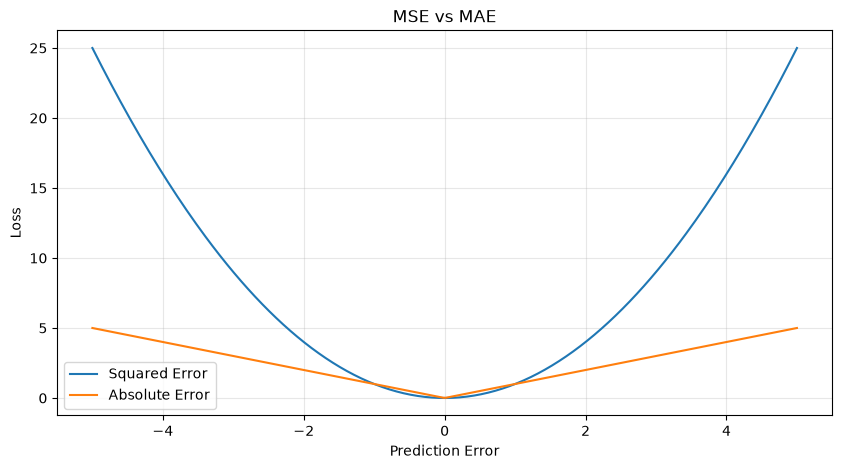

In [3]:
import numpy as np
import matplotlib.pyplot as plt


### 建立誤差範圍
errors = np.linspace(-5, 5, 300)


### 計算 MSE 與 MAE 對單一誤差的損失
mse_values = errors ** 2
mae_values = np.abs(errors)


### 建立畫布
plt.figure(figsize=(10, 5))


### 繪製 MSE
plt.plot(
    errors,
    mse_values,
    label="Squared Error"
)


### 繪製 MAE
plt.plot(
    errors,
    mae_values,
    label="Absolute Error"
)


### 設定圖表
plt.title("MSE vs MAE")
plt.xlabel("Prediction Error")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)


### 顯示圖表
plt.show()

## 二元交叉熵 (Binary Cross Entropy, BCE)

### 什麼是 Binary Cross Entropy？

前面的 MSE 與 MAE 主要用於迴歸問題。

如果模型要預測的是：

```text
0 = 沒有購買
1 = 有購買
```

這種二元分類問題，就經常使用 Binary Cross Entropy (BCE，二元交叉熵)。

$$ \boxed{ BCE=-[y\log(p)+(1-y)\log(1-p)] } $$

其中：

| 符號         | 說明          |
| ---------- | ----------- |
| \\(y\\)    | 真實答案，0 或 1  |
| \\(p\\)    | 模型預測為 1 的機率 |
| \\(\log\\) | 自然對數        |

BCE 不只是看預測類別有沒有正確，而是會根據模型給出的機率，衡量預測結果與真實答案之間的差距。

例如某位顧客實際有購買商品：

```
Target = 1
```

三個模型分別預測：

| 模型 | 購買機率 | 分類結果 (門檻 0.5) | BCE 約 |
| -- | ---- | ------------- | ----- |
| A  | 0.95 | 正確            | 0.051 |
| B  | 0.60 | 正確            | 0.511 |
| C  | 0.10 | 錯誤            | 2.303 |

Model A 與 Model B 都分類正確，但 Model A 對正確答案給出更高機率，因此 BCE 較低。

Model C 對實際為 1 的樣本給出非常低的機率，因此受到較大的懲罰。

> 模型對正確答案越有信心，BCE 通常越小；模型越有信心地預測錯誤，BCE 就越大。

### 實作：使用 PyTorch 的 BCELoss

In [4]:
import torch
import torch.nn as nn


### 建立真實答案
y_true = torch.tensor([
    [1.0],
    [0.0],
    [1.0]
])


### 建立預測機率
y_prob = torch.tensor([
    [0.95],
    [0.20],
    [0.70]
])


### 建立 BCE Loss
criterion = nn.BCELoss()


### 計算 BCE
loss = criterion(y_prob, y_true)


### 顯示結果
print("BCE：", loss.item())

BCE： 0.21037061512470245


## 多類別交叉熵 (Cross Entropy)

### 什麼是 Cross Entropy？

如果模型需要在三個以上互斥類別中選出一個答案，通常使用 Cross Entropy。

例如，我們想讓 ANN 判斷圖片屬於：

```text
0 = Cat
1 = Dog
2 = Rabbit
```

模型輸出：

```text
Cat    2.0
Dog    1.0
Rabbit 0.1
```

這些原始分數稱為 Logits。

經過 Softmax 後，可以轉換成一組機率：

```text
Cat    0.659
Dog    0.242
Rabbit 0.099
```

如果真實答案是 Cat，模型對正確類別給出的機率越高，Cross Entropy 通常越小。

### Cross Entropy 的基本公式

對單筆互斥多類別資料，可以寫成：

$$ \boxed{ CE=-\sum\_{i=1}^{K}y_i\log(p_i) } $$

其中：

| 符號        | 說明               |
| --------- | ---------------- |
| \\(K\\)   | 類別總數             |
| \\(y_i\\) | 真實類別的 One-Hot 標籤 |
| \\(p_i\\) | 第 i 個類別的預測機率     |

如果真實答案只有一個類別，公式可以理解成：

$$ CE=-\log(\text{正確類別的預測機率}) $$

例如真實答案是 Cat，而模型預測 Cat 的機率為 0.659：

$$ CE=-\log(0.659)\approx0.417 $$

### 實作：使用 PyTorch 實作 CrossEntropyLoss

In [5]:
import torch
import torch.nn as nn


### 建立兩筆資料的 Logits
logits = torch.tensor([
    [2.0, 1.0, 0.1],
    [0.5, 2.5, 0.3]
])


### 建立真實類別
y_true = torch.tensor([
    0, # 第一筆是 Cat
    1  # 第二筆是 Dog
], dtype=torch.long)


### 建立 Cross Entropy Loss
criterion = nn.CrossEntropyLoss()


### 計算 Loss
loss = criterion(logits, y_true)


### 顯示結果
print("Cross Entropy：", loss.item())

Cross Entropy： 0.31853973865509033


## 梯度 (Gradient)

梯度 (Gradient) 可以理解成：「當模型參數稍微改變時，Loss 會朝哪個方向變化，以及變化有多快。」

![](./assets/梯度.png)

### 實作：使用 PyTorch 計算梯度

In [6]:
import torch


### 建立 Weight
w = torch.tensor(
    2.0,
    requires_grad=True
)


### 建立輸入與真實答案
x = torch.tensor(2.0)
y_true = torch.tensor(10.0)


### 計算預測值
y_pred = w * x


### 計算 Loss
loss = (y_pred - y_true) ** 2


### 執行反向傳播
loss.backward()


### 顯示結果
print("Prediction：", y_pred.item())
print("Loss：", loss.item())
print("Gradient：", w.grad.item())

Prediction： 4.0
Loss： 36.0
Gradient： -24.0


## 反向傳播 (Backpropagation)

反向傳播 (Backpropagation) 是神經網路計算參數梯度的核心方法。

![](./assets/反向傳播.png)

### 實作：使用 PyTorch 手動觀察反向傳播

In [7]:
import torch
import torch.nn as nn


### 固定隨機種子
torch.manual_seed(42)


### 建立簡單神經網路
model = nn.Linear(
    in_features=2,
    out_features=1
)


### 建立輸入資料
X = torch.tensor([
    [2.0, 3.0]
])


### 建立真實答案
y_true = torch.tensor([
    [10.0]
])


### 建立 Loss Function
criterion = nn.MSELoss()


### 清除舊梯度
model.zero_grad()


### 前向傳播
y_pred = model(X)


### 計算 Loss
loss = criterion(y_pred, y_true)


### 反向傳播
loss.backward()


### 顯示結果
print("Prediction：", y_pred)
print("Loss：", loss.item())

print("\nWeight：")
print(model.weight)

print("\nWeight Gradient：")
print(model.weight.grad)

print("\nBias Gradient：")
print(model.bias.grad)

Prediction： tensor([[2.6763]], grad_fn=<AddmmBackward0>)
Loss： 53.63690948486328

Weight：
Parameter containing:
tensor([[0.5406, 0.5869]], requires_grad=True)

Weight Gradient：
tensor([[-29.2949, -43.9423]])

Bias Gradient：
tensor([-14.6474])


### 9.4 使用 Optimizer 更新參數

In [9]:
import torch.optim as optim


### 建立 Optimizer
optimizer = optim.SGD(
    model.parameters(),
    lr=0.01
)


### 儲存更新前的 Weight
old_weight = model.weight.detach().clone()


### 更新參數
optimizer.step()


### 顯示更新前後的 Weight
print("更新前：")
print(old_weight)

print("\n更新後：")
print(model.weight.detach())

更新前：
tensor([[0.5406, 0.5869]])

更新後：
tensor([[0.8336, 1.0263]])




接續前面的程式：

```
import torch.optim as optim### 建立 Optimizeroptimizer = optim.SGD(    model.parameters(),    lr=0.01)### 儲存更新前的 Weightold_weight = model.weight.detach().clone()### 更新參數optimizer.step()### 顯示更新前後的 Weightprint("更新前：")print(old_weight)print("\n更新後：")print(model
```